In [174]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score, RocCurveDisplay

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [99]:
train_data = pd.read_csv("train.csv")

In [100]:
train_data.head()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,139333,0,0.268939,55,0,7.710483,600.0,10,0,2,0,0.0
1,40087,0,0.136173,32,0,0.463846,4300.0,2,0,1,0,0.0
2,75114,0,0.594971,48,0,58.000000,NaN,2,0,0,0,NaN
3,44118,0,0.054019,48,0,0.233234,8051.0,7,0,1,0,0.0
4,65721,0,0.097851,43,1,0.161460,4000.0,12,0,0,0,0.0


In [101]:
train_data.columns

Index(['Id', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='str')

In [102]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 105000 entries, 0 to 104999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    105000 non-null  int64  
 1   SeriousDlqin2yrs                      105000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  105000 non-null  float64
 3   age                                   105000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  105000 non-null  int64  
 5   DebtRatio                             105000 non-null  float64
 6   MonthlyIncome                         84172 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       105000 non-null  int64  
 8   NumberOfTimes90DaysLate               105000 non-null  int64  
 9   NumberRealEstateLoansOrLines          105000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  105000 non-null  int64  
 11  NumberOfDep

In [103]:
train_data.describe()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,105000.000000,105000.000000,105000.000000,105000.000000,105000.000000,105000.000000,8.417200e+04,105000.000000,105000.000000,105000.000000,105000.000000,102229.000000
mean,74893.619543,0.066838,6.412435,52.287181,0.429267,358.327532,6.645492e+03,8.443857,0.274562,1.017629,0.248419,0.757212
std,43299.870021,0.249743,273.643356,14.776255,4.286556,2318.264949,1.550779e+04,5.131864,4.263913,1.142360,4.249771,1.113787
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37310.750000,0.000000,0.029856,41.000000,0.000000,0.174227,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,74821.500000,0.000000,0.154257,52.000000,0.000000,0.366414,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112386.250000,0.000000,0.560586,63.000000,0.000000,0.870590,8.208000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,149999.000000,1.000000,50708.000000,103.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,13.000000


In [104]:
train_data["NumberOfDependents"].value_counts(dropna=False).sort_index()

NumberOfDependents
0.0     60792
1.0     18479
2.0     13587
3.0      6695
4.0      1980
5.0       519
6.0       113
7.0        43
8.0        17
9.0         2
10.0        1
13.0        1
NaN      2771
Name: count, dtype: int64

In [105]:
train_data["NumberOfDependents"] = (
    train_data["NumberOfDependents"].astype("Int64")
)

In [106]:
NaNMonthlyIncome = train_data[train_data["MonthlyIncome"].isna()]

In [107]:
NaNMonthlyIncome

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
2,75114,0,0.594971,48,0,58.0,NaN,2,0,0,0,<NA>
13,136056,0,0.025380,37,0,33.0,NaN,4,0,0,0,0
16,108575,0,0.001971,60,0,1.0,NaN,5,0,0,0,<NA>
19,14604,0,0.001064,93,0,0.0,NaN,3,0,0,0,0
29,43882,0,0.064247,52,0,3612.0,NaN,10,0,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
104954,80205,0,0.012105,65,0,1879.0,NaN,10,0,2,0,0
104971,126667,0,0.000000,61,0,1348.0,NaN,4,0,1,0,0
104977,39792,0,0.007727,54,0,1177.0,NaN,2,0,1,0,0
104978,67326,0,0.405049,73,0,3633.0,NaN,13,0,1,0,0


In [108]:
noMonthlyIncome = train_data[train_data["MonthlyIncome"] == 0]

In [109]:
noMonthlyIncome

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
10,118462,0,0.288020,74,0,3690.0,0.0,13,0,1,0,0
45,53351,0,0.048884,58,0,5213.0,0.0,10,0,3,0,0
82,39191,0,0.008624,71,0,2.0,0.0,2,0,0,0,0
482,22454,0,0.057204,35,0,62.0,0.0,4,0,0,0,0
598,21238,0,0.204292,51,0,548.0,0.0,10,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
104597,135338,0,0.004000,61,0,1182.0,0.0,9,0,2,0,2
104619,131194,0,0.039303,39,0,2688.0,0.0,4,0,2,0,3
104662,768,0,0.002141,89,1,5.0,0.0,4,0,0,0,0
104686,37585,0,0.156265,27,0,111.0,0.0,6,0,0,0,0


<Axes: title={'center': 'Loan Status'}, xlabel='SeriousDlqin2yrs'>

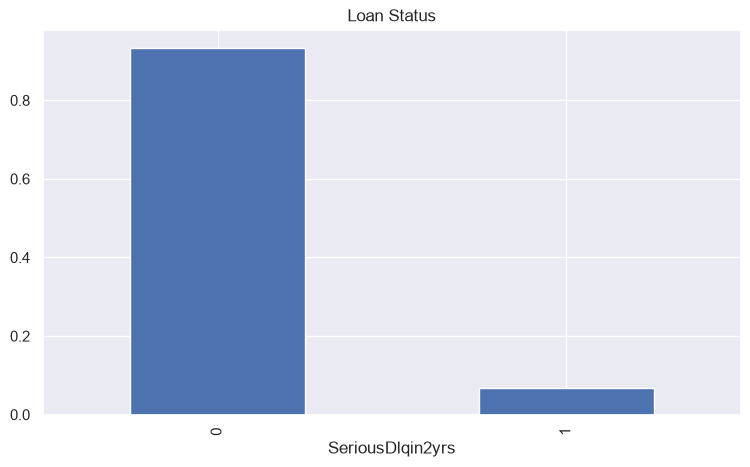

In [110]:
train_data.SeriousDlqin2yrs.value_counts(normalize=True).plot(kind='bar',title="Loan Status")

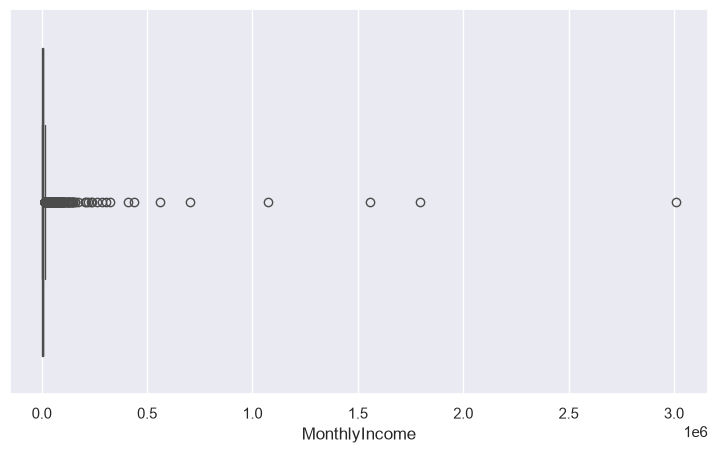

In [111]:
sns.boxplot(x=train_data["MonthlyIncome"])
plt.show()

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

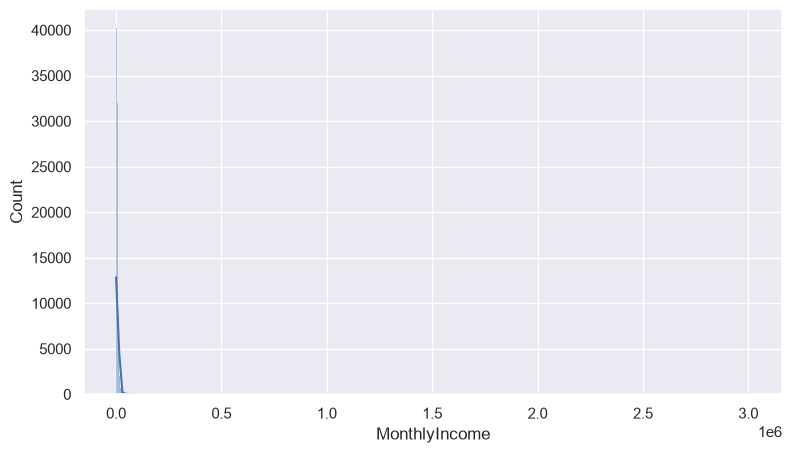

In [112]:
sns.set_theme(rc={"figure.figsize":(9,5)})
sns.histplot(data=train_data, x="MonthlyIncome", kde=True)

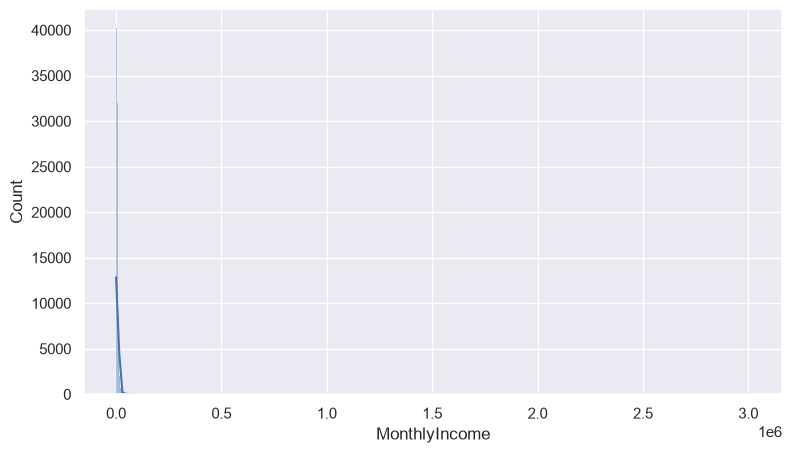

In [113]:
sns.histplot(data=train_data, x="MonthlyIncome", kde=True)
plt.show()

In [114]:
train_data.isna().sum()

Id                                          0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           20828
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       2771
dtype: int64

In [115]:
(train_data.isna().mean() * 100).sort_values(ascending=False)

MonthlyIncome                           19.836190
NumberOfDependents                       2.639048
Id                                       0.000000
SeriousDlqin2yrs                         0.000000
RevolvingUtilizationOfUnsecuredLines     0.000000
age                                      0.000000
NumberOfTime30-59DaysPastDueNotWorse     0.000000
DebtRatio                                0.000000
NumberOfOpenCreditLinesAndLoans          0.000000
NumberOfTimes90DaysLate                  0.000000
NumberRealEstateLoansOrLines             0.000000
NumberOfTime60-89DaysPastDueNotWorse     0.000000
dtype: float64

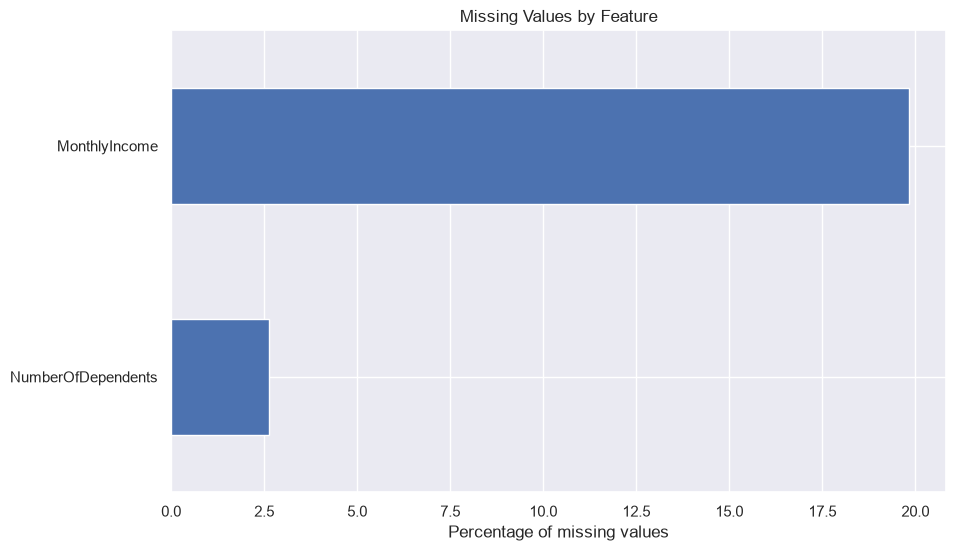

In [116]:
missing_pct = train_data.isna().mean() * 100

missing_pct[missing_pct > 0].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Percentage of missing values")
plt.title("Missing Values by Feature")
plt.show()

In [117]:
column = "MonthlyIncome"

Q1 = train_data[column].quantile(0.25)
Q3 = train_data[column].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = train_data[
    (train_data[column] < lower_bound) |
    (train_data[column] > upper_bound)
]

print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / train_data[column].notna().sum() * 100)

Number of outliers: 3451
Percentage: 4.099938221736445


In [118]:
outliers.sort_values(by="MonthlyIncome", ascending=False)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
64705,73764,0,0.007328,52,0,0.001470,3008750.0,10,0,1,0,3
25419,137141,0,0.000000,68,0,0.002776,1794060.0,15,0,1,0,0
14801,111366,0,0.163856,44,0,0.004013,1560100.0,12,0,4,0,2
71220,50641,0,0.469025,44,1,0.004537,1072500.0,9,0,2,0,1
95371,93565,0,0.071628,50,0,0.008268,702500.0,12,0,4,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
35779,79815,0,0.132081,57,0,0.227158,15442.0,14,0,1,0,2
41663,103281,0,0.118193,63,0,0.281262,15433.0,9,0,2,0,1
63639,113858,0,0.681566,58,0,0.177752,15425.0,9,0,1,0,1
42516,48846,1,0.174452,46,2,0.294762,15425.0,14,0,4,0,1


<Axes: xlabel='NumberOfDependents'>

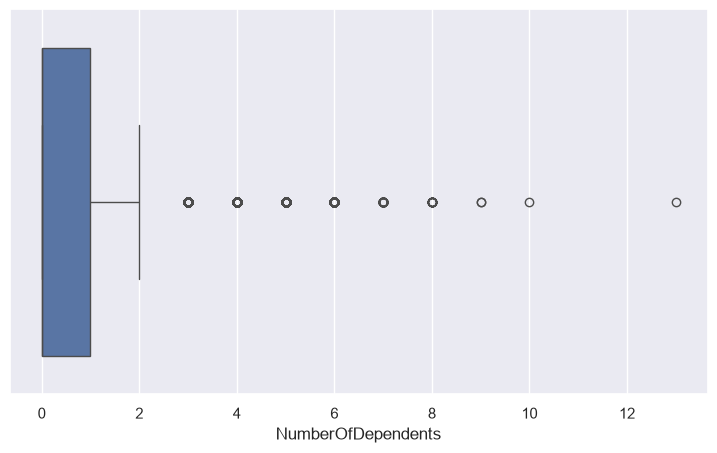

In [119]:
sns.boxplot(x=train_data["NumberOfDependents"])

In [120]:
column = "NumberOfDependents"

Q1 = train_data[column].quantile(0.25)
Q3 = train_data[column].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = train_data[
    (train_data[column] < lower_bound) |
    (train_data[column] > upper_bound)
]

print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / train_data[column].notna().sum() * 100)

Number of outliers: 9371
Percentage: 9.166674818300091


In [121]:
outliers.sort_values(by="NumberOfDependents", ascending=False)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
102034,128035,0,1.000000,53,1,0.230054,3333.0,3,1,1,0,13
21648,39096,0,0.079194,60,0,0.133582,7500.0,10,0,0,0,10
85649,44849,0,1.000000,38,0,0.643728,2789.0,5,0,1,0,9
70683,137561,0,0.033831,48,0,0.207236,16666.0,8,0,1,0,9
30299,18803,1,1.078335,39,2,0.124300,1785.0,6,1,0,0,8
...,...,...,...,...,...,...,...,...,...,...,...,...
40669,40786,1,0.211747,49,0,0.573242,6300.0,27,0,2,0,3
40661,99037,0,0.411243,37,0,0.161327,4400.0,7,0,0,0,3
40640,22903,1,0.924303,27,1,0.215302,2600.0,3,0,0,1,3
40635,47468,0,0.357216,58,0,0.529550,3400.0,11,0,2,0,3


<Axes: xlabel='NumberOfDependents', ylabel='Count'>

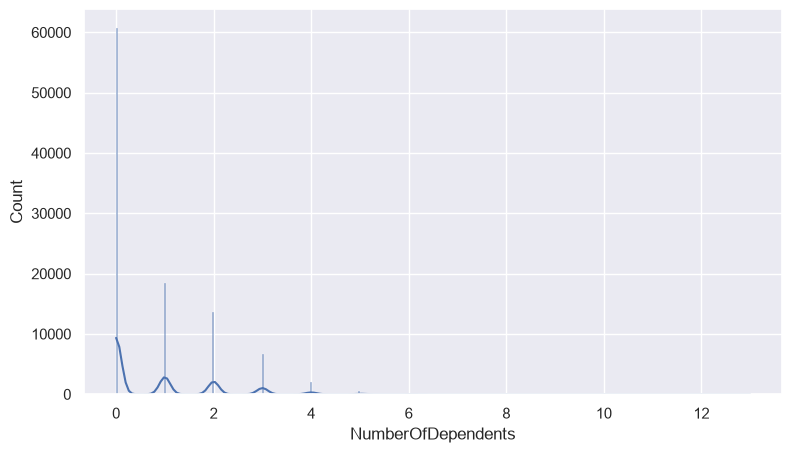

In [122]:
sns.histplot(data=train_data, x="NumberOfDependents", kde=True)

In [123]:
np.max(train_data["NumberOfDependents"])

np.int64(13)

In [124]:
np.mean(train_data["NumberOfDependents"])

np.float64(0.7572117500904831)

# -------------------------------------------------------------------------------------

In [125]:
from sklearn.model_selection import train_test_split

In [126]:
# Limpieza de valores erróneos (reglas fijas, no usan estadísticas del dataset -> sin leakage)
PAST_DUE_COLS = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
ERROR_VALUE_COLS = PAST_DUE_COLS + ["age", "RevolvingUtilizationOfUnsecuredLines"]

def clean_data(df):
    df = df.copy()
    # 96 y 98 son códigos de error, no conteos reales -> NaN
    df[PAST_DUE_COLS] = df[PAST_DUE_COLS].astype(float).replace({96: np.nan, 98: np.nan})
    # Edad menor a 18 no es válida (hay un registro con age = 0) -> NaN
    df["age"] = df["age"].astype(float).where(df["age"] >= 18)
    # Utilización > 10 (más de 1000% del límite) es un error de captura -> NaN
    df["RevolvingUtilizationOfUnsecuredLines"] = df["RevolvingUtilizationOfUnsecuredLines"].where(
        df["RevolvingUtilizationOfUnsecuredLines"] <= 10
    )
    # Cuando falta MonthlyIncome, DebtRatio es la deuda en dólares, no un ratio -> lo marcamos
    df["MonthlyIncome_missing"] = df["MonthlyIncome"].isna().astype(int)
    return df

train_data = clean_data(train_data)


In [127]:
# Separamos features de labels
X = train_data.drop(columns=["SeriousDlqin2yrs", "Id"])
y = train_data["SeriousDlqin2yrs"]

In [128]:
# Split 70% train, 15% validatio, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [129]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [130]:
# Creamos copias de los datos
X_train_processed = X_train.copy()
X_val_processed = X_val.copy()
X_test_processed = X_test.copy()

In [131]:
income_imputer = SimpleImputer(strategy="median")
dependents_imputer = SimpleImputer(strategy="most_frequent")
error_values_imputer = SimpleImputer(strategy="median")

In [132]:
# Entrenamos inputers solo con datos de train
income_imputer.fit(X_train[["MonthlyIncome"]])


,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['MonthlyIncome']
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](1,)",[5400.]


In [133]:
dependents_imputer.fit(X_train[["NumberOfDependents"]])
error_values_imputer.fit(X_train[ERROR_VALUE_COLS])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse','NumberOfTimes90DaysLate','age', 'RevolvingUtilizationOfUnsecuredLines']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](5,)","[ 0. , 0. , 0. ,52. , 0.15]"


In [134]:
for dataset in [X_train_processed, X_val_processed, X_test_processed]:
    dataset["MonthlyIncome"] = income_imputer.transform(
        dataset[["MonthlyIncome"]]
    ).ravel()

    dataset["NumberOfDependents"] = dependents_imputer.transform(
        dataset[["NumberOfDependents"]]
    ).ravel()

    dataset[ERROR_VALUE_COLS] = error_values_imputer.transform(
        dataset[ERROR_VALUE_COLS]
    )

In [135]:
# Verificamos que ya no hay NANs
print("Training missing values:")
print(X_train_processed.isna().sum())

print("\nValidation missing values:")
print(X_val_processed.isna().sum())

print("\nTest missing values:")
print(X_test_processed.isna().sum())

Training missing values:
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
MonthlyIncome_missing                   0
dtype: int64

Validation missing values:
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
MonthlyIncome_missing                   0
dtype: int

## EDA

### Monthly Income

El histograma de "MonthlyIncome" se distorciona por los valores extremos. En el dataset hay 3 personas con income mayor a un millón. 

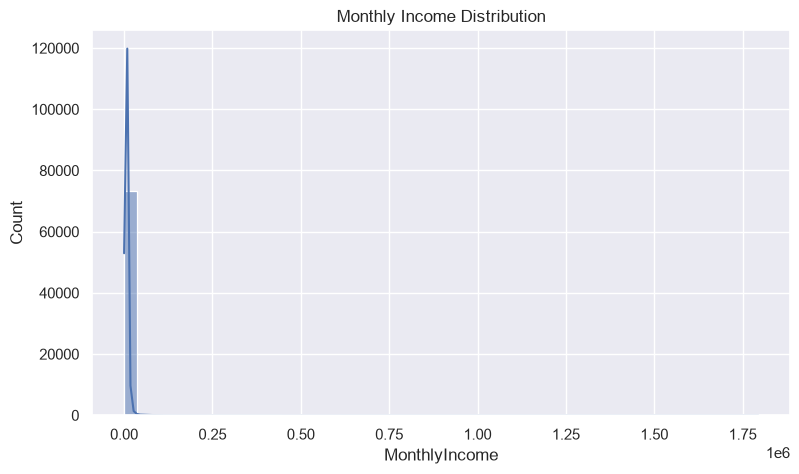

In [136]:
sns.histplot(
    data=X_train_processed,
    x="MonthlyIncome",
    bins=50,
    kde=True
)

plt.title("Monthly Income Distribution")
plt.show()

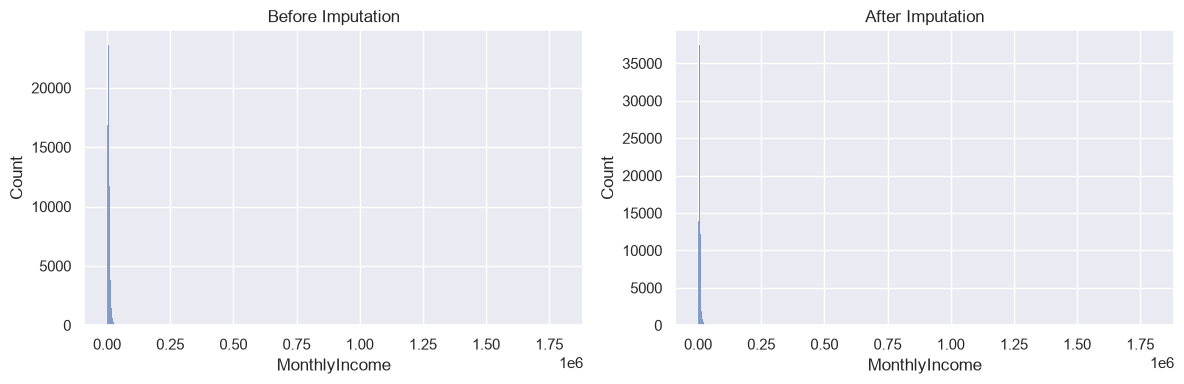

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train["MonthlyIncome"], ax=axes[0])
axes[0].set_title("Before Imputation")

sns.histplot(X_train_processed["MonthlyIncome"], ax=axes[1])
axes[1].set_title("After Imputation")

plt.tight_layout()
plt.show()

In [138]:
X_train_processed["MonthlyIncome"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

count    7.350000e+04
mean     6.380860e+03
std      1.152369e+04
min      0.000000e+00
50%      5.400000e+03
75%      7.381000e+03
90%      1.066720e+04
95%      1.348200e+04
99%      2.258811e+04
99.9%    7.000000e+04
max      1.794060e+06
Name: MonthlyIncome, dtype: float64

In [139]:
X_train_processed["MonthlyIncome"].nlargest(10)

25419    1794060.0
14801    1560100.0
71220    1072500.0
95371     702500.0
98846     440000.0
39193     324000.0
50897     304000.0
8389      261666.0
86827     218674.0
83414     208333.0
Name: MonthlyIncome, dtype: float64

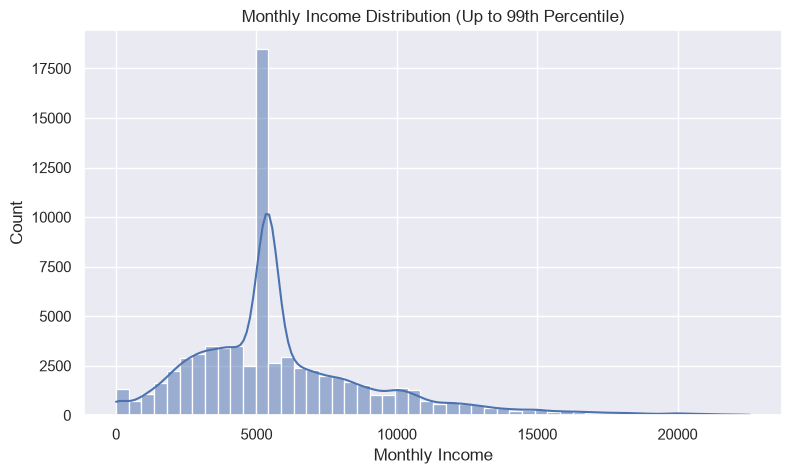

In [140]:
income = X_train_processed["MonthlyIncome"]

p99 = income.quantile(0.99)

sns.histplot(
    income[income <= p99],
    bins=50,
    kde=True
)

plt.title("Monthly Income Distribution (Up to 99th Percentile)")
plt.xlabel("Monthly Income")
plt.show()

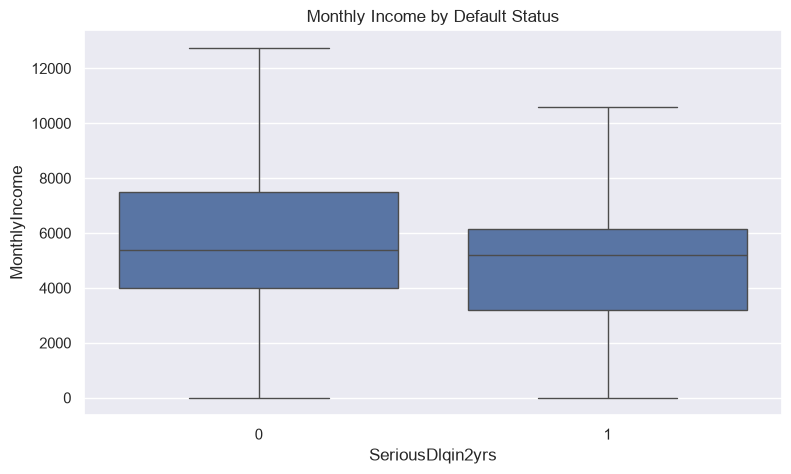

In [141]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="MonthlyIncome",
    showfliers=False
)

plt.title("Monthly Income by Default Status")
plt.show()

### Debt Ratio: liabilities / assets

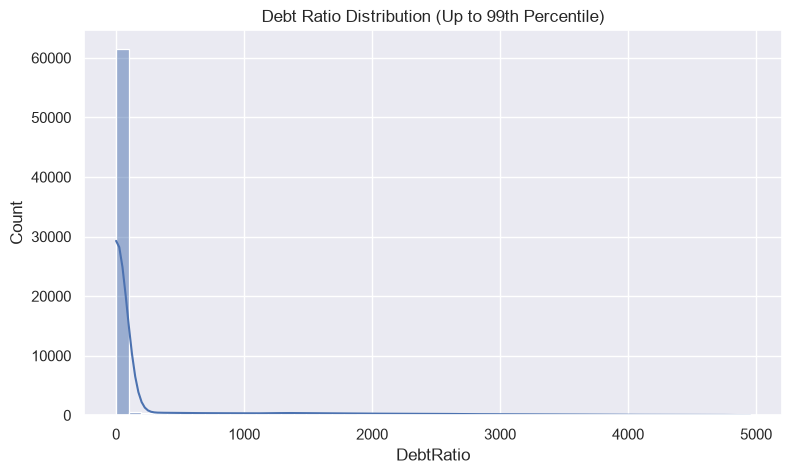

In [142]:
debtRatio = X_train_processed["DebtRatio"]

p99_debtRatio = debtRatio.quantile(0.99)

sns.histplot(
    data=X_train_processed,
    x=debtRatio[debtRatio < p99_debtRatio],
    bins=50,
    kde=True
)

plt.title("Debt Ratio Distribution (Up to 99th Percentile)")
plt.show()

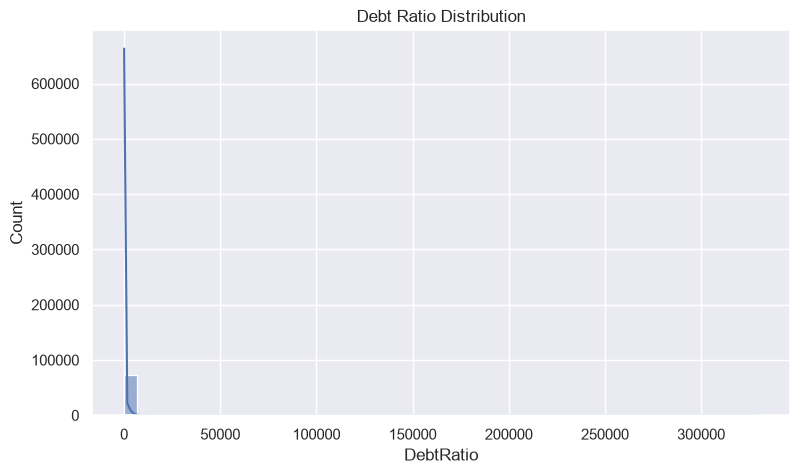

In [143]:
sns.histplot(
    data=X_train_processed,
    x="DebtRatio",
    bins=50,
    kde=True
)

plt.title("Debt Ratio Distribution")
plt.show()

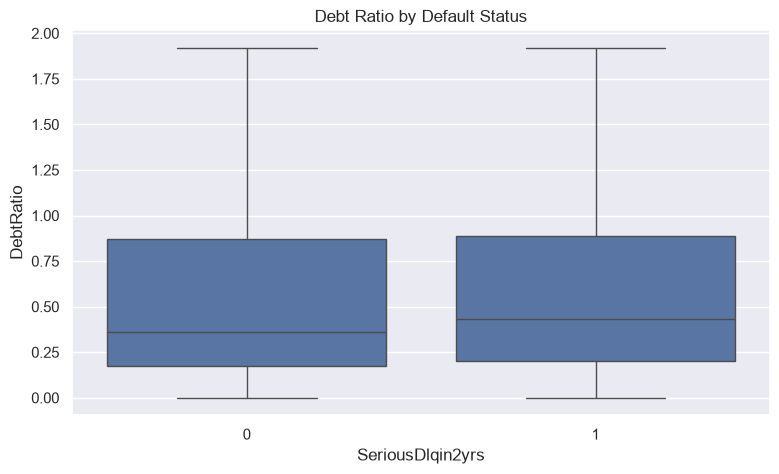

In [144]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="DebtRatio",
    showfliers=False
)

plt.title("Debt Ratio by Default Status")
plt.show()

### RevolvingUtilizationOfUnsecuredLines

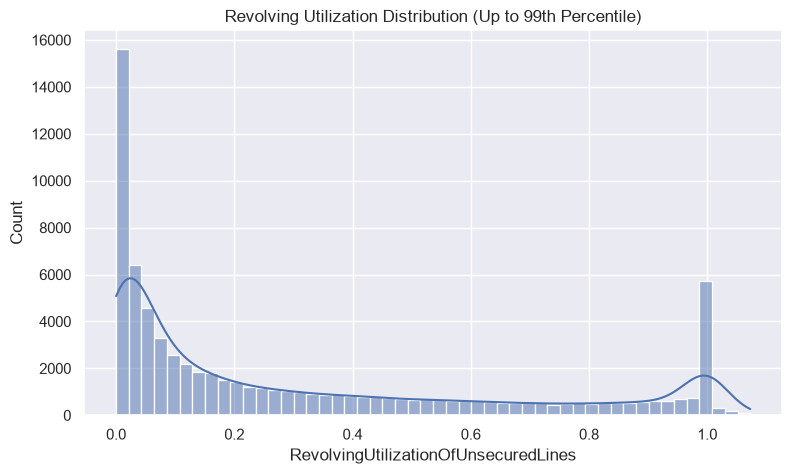

In [145]:
revolvingUtil = X_train_processed["RevolvingUtilizationOfUnsecuredLines"]

p99_revolvingUtil = revolvingUtil.quantile(0.99)

sns.histplot(
    data=X_train_processed,
    x=revolvingUtil[revolvingUtil < p99_revolvingUtil],
    bins=50,
    kde=True
)

plt.title("Revolving Utilization Distribution (Up to 99th Percentile)")
plt.show()

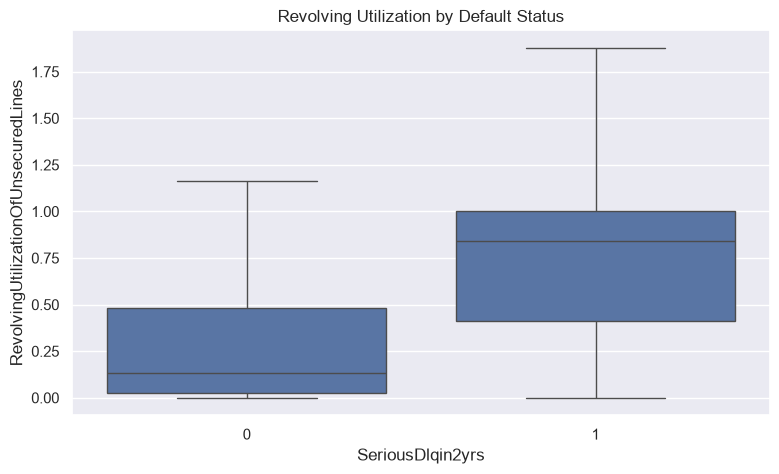

In [146]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="RevolvingUtilizationOfUnsecuredLines",
    showfliers=False
)

plt.title("Revolving Utilization by Default Status")
plt.show()

### Age

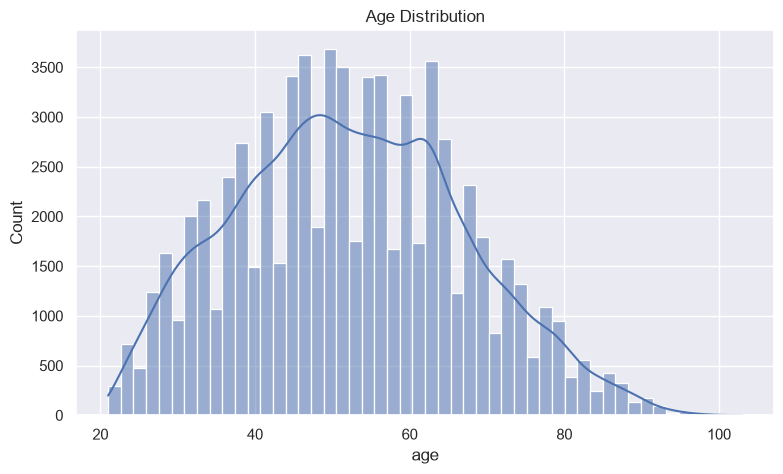

In [147]:
sns.histplot(
    data=X_train_processed,
    x="age",
    bins=50,
    kde=True
)

plt.title("Age Distribution")
plt.show()

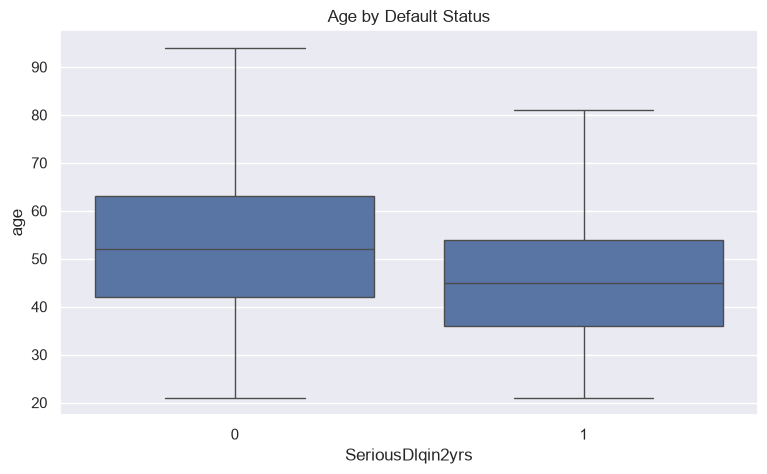

In [148]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="age",
    showfliers=False
)

plt.title("Age by Default Status")
plt.show()

<Axes: >

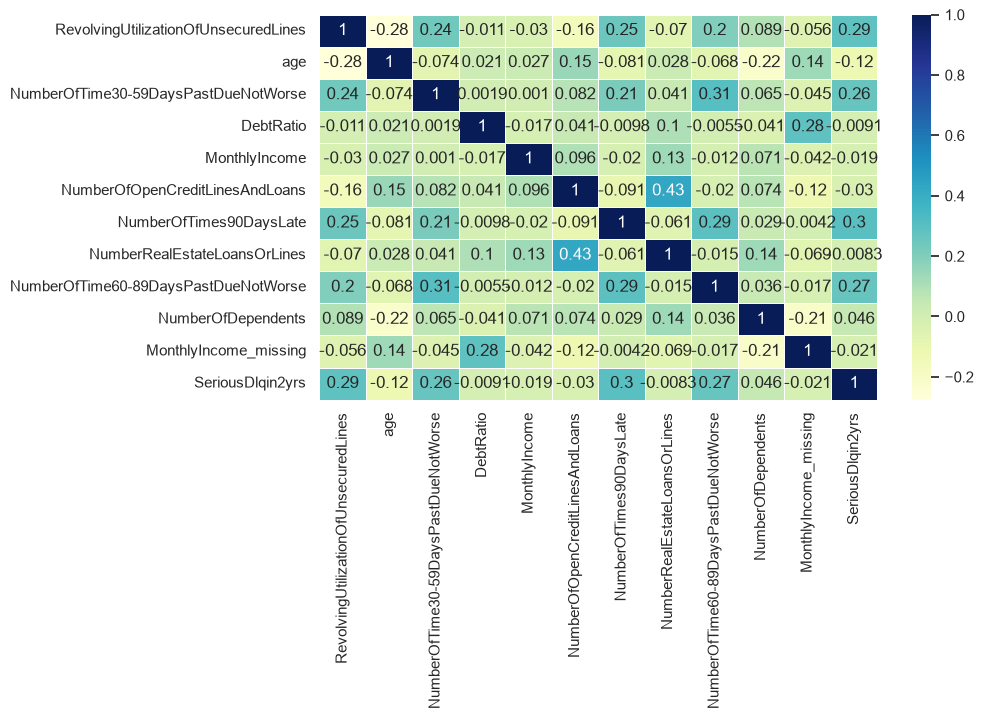

In [149]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

correlation_mat = train_analysis.corr(numeric_only=True)
sns.heatmap(correlation_mat,annot=True,linewidths=0.5,cmap="YlGnBu")

### Number of dependents

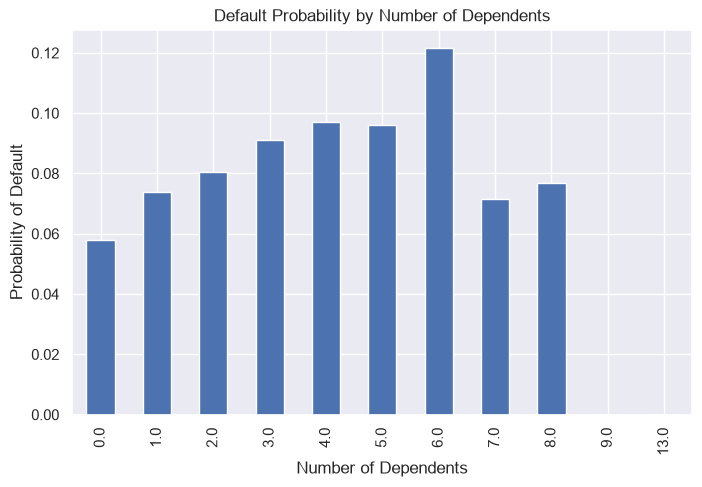

In [150]:
# Combine training features with the target
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

# Calculate default probability
default_rates = train_analysis.groupby(
    "NumberOfDependents"
)["SeriousDlqin2yrs"].mean()

# Plot
default_rates.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Number of Dependents")
plt.ylabel("Probability of Default")
plt.title("Default Probability by Number of Dependents")
plt.show()

<Axes: xlabel='NumberOfDependents', ylabel='count'>

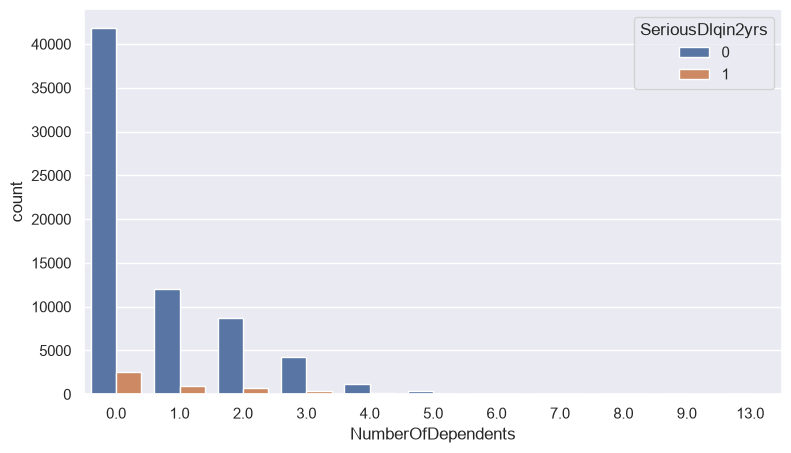

In [151]:
sns.countplot(x="NumberOfDependents", hue="SeriousDlqin2yrs", data=train_analysis)

### Number of Open Credit Cards and Loans

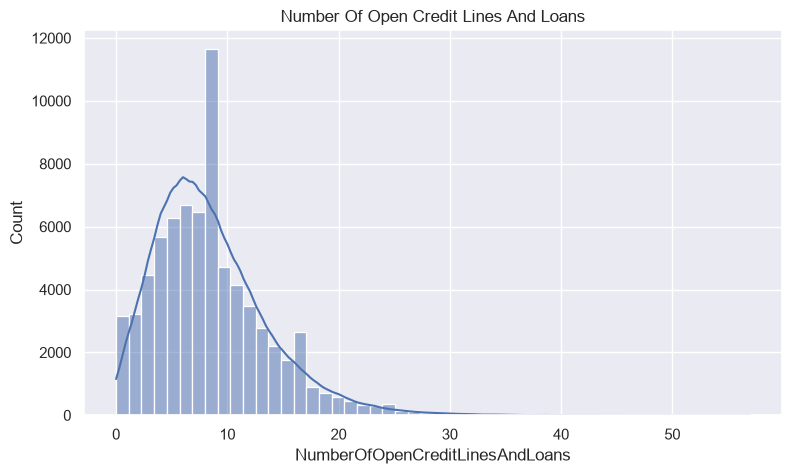

In [152]:
sns.histplot(
    data=X_train_processed,
    x="NumberOfOpenCreditLinesAndLoans",
    bins=50,
    kde=True
)

plt.title("Number Of Open Credit Lines And Loans")
plt.show()

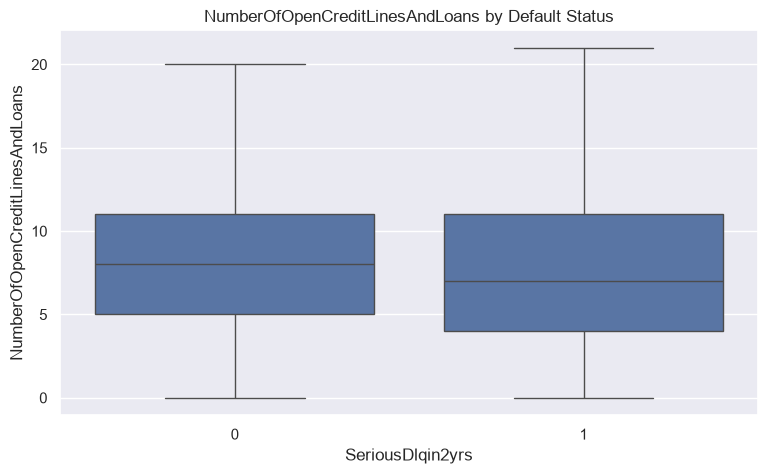

In [153]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="NumberOfOpenCreditLinesAndLoans",
    showfliers=False
)

plt.title("NumberOfOpenCreditLinesAndLoans by Default Status")
plt.show()

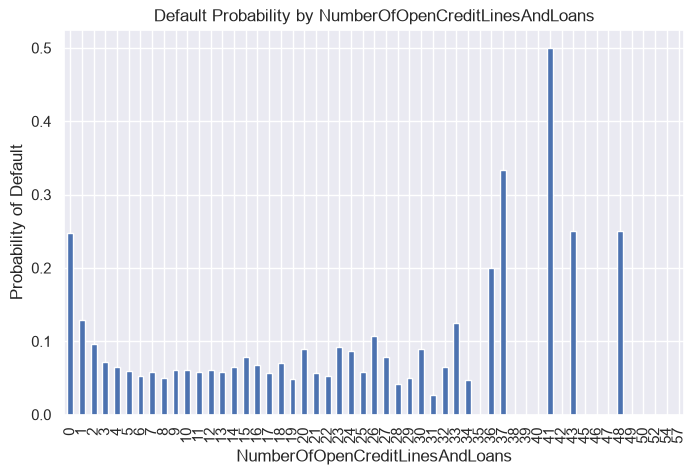

In [154]:
# Combine training features with the target
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

# Calculate default probability
default_rates = train_analysis.groupby(
    "NumberOfOpenCreditLinesAndLoans"
)["SeriousDlqin2yrs"].mean()

# Plot
default_rates.plot(kind="bar", figsize=(8, 5))

plt.xlabel("NumberOfOpenCreditLinesAndLoans")
plt.ylabel("Probability of Default")
plt.title("Default Probability by NumberOfOpenCreditLinesAndLoans")
plt.show()

<Axes: xlabel='NumberOfOpenCreditLinesAndLoans', ylabel='count'>

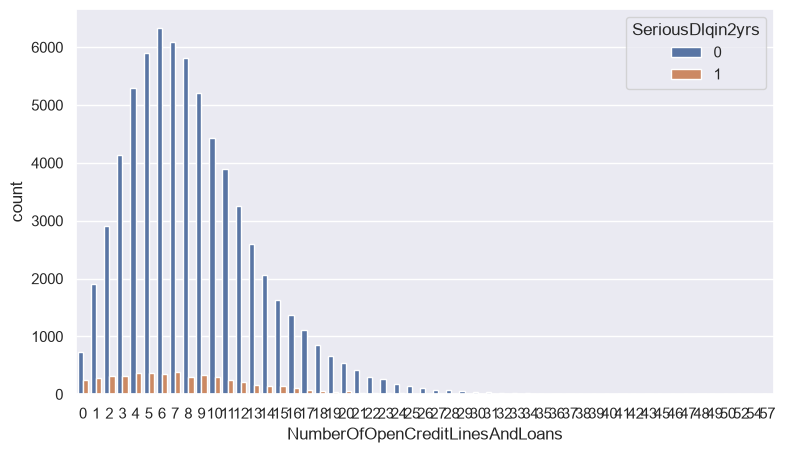

In [155]:
sns.countplot(x="NumberOfOpenCreditLinesAndLoans", hue="SeriousDlqin2yrs", data=train_analysis)

### NumberOfTimes90DaysLate

<Axes: xlabel='NumberOfTimes90DaysLate', ylabel='count'>

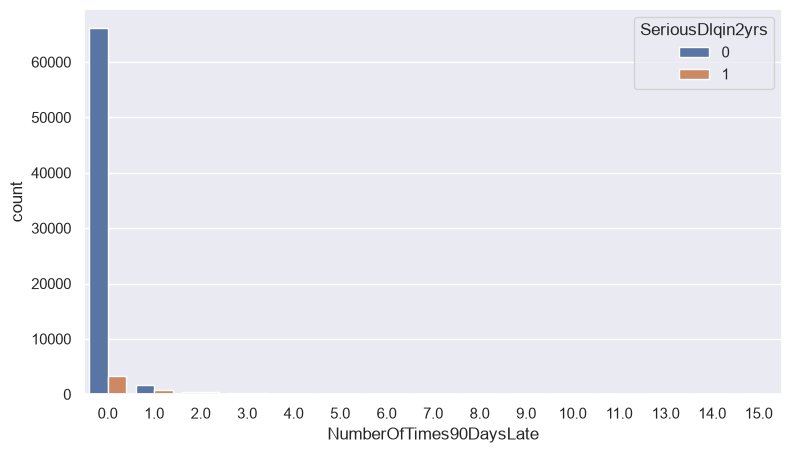

In [156]:
sns.countplot(x="NumberOfTimes90DaysLate", hue="SeriousDlqin2yrs", data=train_analysis)

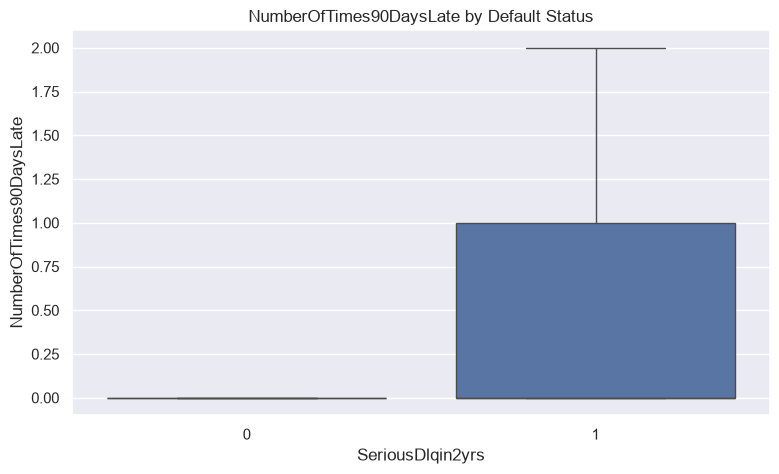

In [157]:
train_analysis = X_train_processed.copy()
train_analysis["SeriousDlqin2yrs"] = y_train

sns.boxplot(
    data=train_analysis,
    x="SeriousDlqin2yrs",
    y="NumberOfTimes90DaysLate",
    showfliers=False
)

plt.title("NumberOfTimes90DaysLate by Default Status")
plt.show()

# Logistic Regression

In [158]:
baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

In [159]:
baseline.fit(X_train_processed, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['RevolvingUtilizationOfUnsecuredLines','age', 'NumberOfTime30-59DaysPastDueNotWorse',..., 'NumberOfTime60-89DaysPastDueNotWorse','NumberOfDependents', 'MonthlyIncome_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [160]:
baseline_auc = roc_auc_score(
    y_val,
    baseline.predict_proba(X_val_processed)[:, 1]
)

In [161]:
print("Baseline AUC:", baseline_auc)

Baseline AUC: 0.847643610168842


#### Predicted probabilities

In [162]:
# Predicted probabilities of default
y_prob = baseline.predict_proba(X_val_processed)[:, 1]

# Predicted classes (default threshold = 0.5)
y_pred = baseline.predict(X_val_processed)

In [163]:
# Predicted probabilities
y_prob = baseline.predict_proba(X_val_processed)[:, 1]

# Predicted classes (default threshold = 0.5)
y_pred = baseline.predict(X_val_processed)

# Evaluation metrics
baseline_auc = roc_auc_score(y_val, y_prob)
baseline_precision = precision_score(y_val, y_pred, zero_division=0)
baseline_recall = recall_score(y_val, y_pred, zero_division=0)
baseline_f1 = f1_score(y_val, y_pred, zero_division=0)

print(f"ROC-AUC:   {baseline_auc:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

ROC-AUC:   0.8476
Precision: 0.5560
Recall:    0.1462
F1-score:  0.2316


ROC-AUC: 0.8476


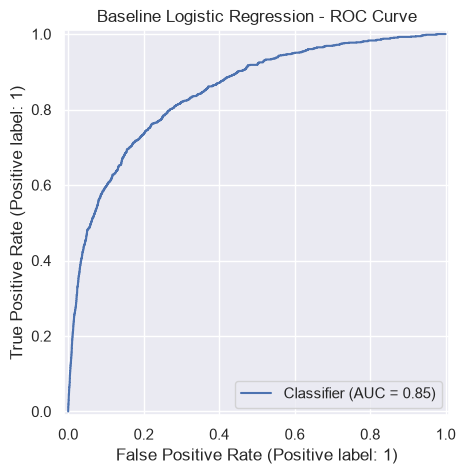

In [164]:
auc = roc_auc_score(y_val, y_prob)

print(f"ROC-AUC: {auc:.4f}")

RocCurveDisplay.from_predictions(
    y_val,
    y_prob
)

plt.title("Baseline Logistic Regression - ROC Curve")
plt.show()

In [165]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.99      0.97     14697
           1       0.56      0.15      0.23      1053

    accuracy                           0.94     15750
   macro avg       0.75      0.57      0.60     15750
weighted avg       0.92      0.94      0.92     15750



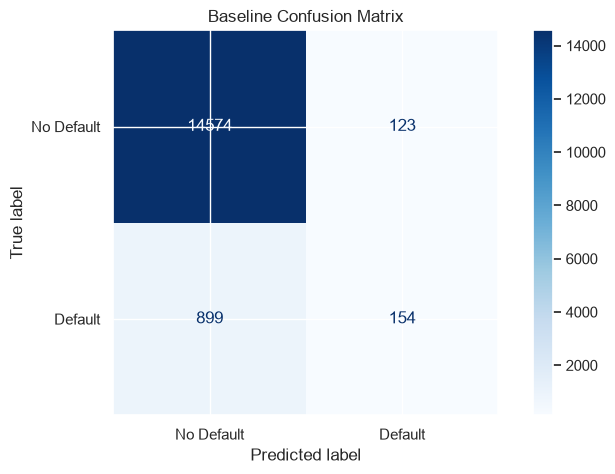

In [166]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix")
plt.show()

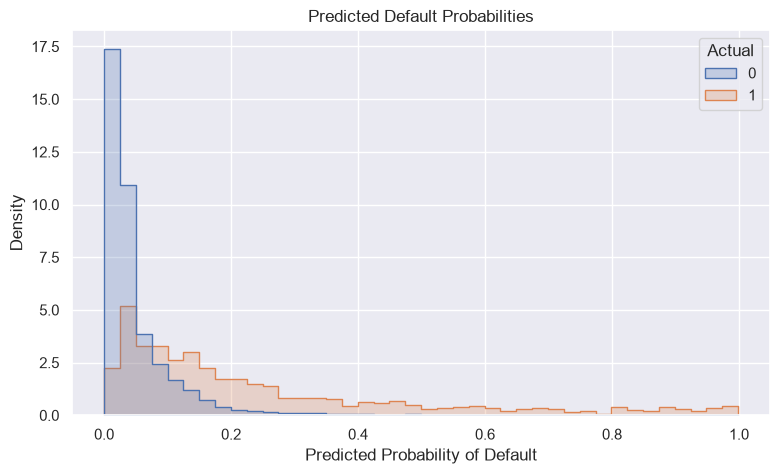

In [167]:
results = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "PredictedProbability": y_prob
})

sns.histplot(
    data=results,
    x="PredictedProbability",
    hue="Actual",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Predicted Default Probabilities")
plt.xlabel("Predicted Probability of Default")
plt.show()

In [168]:
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    predictions = (y_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_val, predictions, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val, predictions, zero_division=0):.3f} | "
        f"F1: {f1_score(y_val, predictions, zero_division=0):.3f}"
    )

Threshold: 0.1 | Precision: 0.256 | Recall: 0.651 | F1: 0.368
Threshold: 0.2 | Precision: 0.447 | Recall: 0.411 | F1: 0.428
Threshold: 0.3 | Precision: 0.499 | Recall: 0.275 | F1: 0.355
Threshold: 0.4 | Precision: 0.552 | Recall: 0.205 | F1: 0.299
Threshold: 0.5 | Precision: 0.556 | Recall: 0.146 | F1: 0.232


In [169]:
coefficients = pd.Series(
    baseline.named_steps["logisticregression"].coef_[0],
    index=X_train_processed.columns
)

print(coefficients.sort_values())

MonthlyIncome                          -0.346275
age                                    -0.284665
DebtRatio                              -0.219816
NumberOfDependents                      0.044711
MonthlyIncome_missing                   0.066263
NumberRealEstateLoansOrLines            0.120225
NumberOfOpenCreditLinesAndLoans         0.128907
NumberOfTime60-89DaysPastDueNotWorse    0.209190
NumberOfTime30-59DaysPastDueNotWorse    0.289526
NumberOfTimes90DaysLate                 0.290546
RevolvingUtilizationOfUnsecuredLines    0.689170
dtype: float64


#### Random Forest

ROC-AUC:           0.8432
Average Precision: 0.3457
Precision:         0.5251
Recall:            0.1690
F1-score:          0.2557


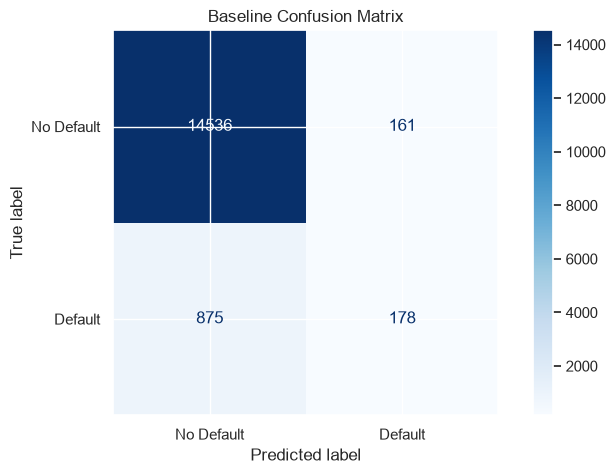

Training AUC:   1.0000
Validation AUC: 0.8432


In [172]:
from sklearn.metrics import average_precision_score


for n_estimator in [400]:
    rf_baseline = RandomForestClassifier(
        n_estimators=n_estimator,
        random_state=42,
        n_jobs=-1
    )

    rf_baseline.fit(X_train_processed, y_train)

    # Predicted probabilities
    rf_probs = rf_baseline.predict_proba(X_val_processed)[:, 1]

    # Predicted classes
    rf_pred = rf_baseline.predict(X_val_processed)

    # Metrics
    rf_auc = roc_auc_score(y_val, rf_probs)
    rf_ap = average_precision_score(y_val, rf_probs)
    rf_precision = precision_score(y_val, rf_pred, zero_division=0)
    rf_recall = recall_score(y_val, rf_pred, zero_division=0)
    rf_f1 = f1_score(y_val, rf_pred, zero_division=0)

    print(f"ROC-AUC:           {rf_auc:.4f}")
    print(f"Average Precision: {rf_ap:.4f}")
    print(f"Precision:         {rf_precision:.4f}")
    print(f"Recall:            {rf_recall:.4f}")
    print(f"F1-score:          {rf_f1:.4f}")

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        rf_pred,
        display_labels=["No Default", "Default"],
        cmap="Blues"
    )

    plt.title("Baseline Confusion Matrix")
    plt.show()

    train_auc = roc_auc_score(
        y_train,
        rf_baseline.predict_proba(X_train_processed)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val,
        rf_baseline.predict_proba(X_val_processed)[:, 1]
    )

    print(f"Training AUC:   {train_auc:.4f}")
    print(f"Validation AUC: {val_auc:.4f}")


In [173]:
late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for col in late_cols:
    print(f"\n{col}")
    print(X_train[col].value_counts().sort_index())


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0.0     61818
1.0      7855
2.0      2187
3.0       855
4.0       363
5.0       176
6.0        66
7.0        22
8.0        11
9.0         6
10.0        1
11.0        1
12.0        1
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0.0     69806
1.0      2751
2.0       565
3.0       158
4.0        47
5.0        19
6.0         8
7.0         5
8.0         1
9.0         1
11.0        1
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0.0     69408
1.0      2546
2.0       754
3.0       353
4.0       147
5.0        57
6.0        44
7.0        18
8.0        12
9.0        13
10.0        2
11.0        1
13.0        3
14.0        2
15.0        2
Name: count, dtype: int64


#### Gradient Boosting

In [179]:
gb_baseline = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_baseline.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",400
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [180]:
# Predicted default probabilities
gb_probs = gb_baseline.predict_proba(X_val_processed)[:, 1]

# Predicted classes at threshold 0.5
gb_pred = gb_baseline.predict(X_val_processed)

# Evaluation
gb_auc = roc_auc_score(y_val, gb_probs)
gb_ap = average_precision_score(y_val, gb_probs)
gb_precision = precision_score(y_val, gb_pred, zero_division=0)
gb_recall = recall_score(y_val, gb_pred, zero_division=0)
gb_f1 = f1_score(y_val, gb_pred, zero_division=0)

In [181]:
print(f"ROC-AUC:           {gb_auc:.4f}")
print(f"Average Precision: {gb_ap:.4f}")
print(f"Precision:         {gb_precision:.4f}")
print(f"Recall:            {gb_recall:.4f}")
print(f"F1-score:          {gb_f1:.4f}")

ROC-AUC:           0.8582
Average Precision: 0.3817
Precision:         0.5633
Recall:            0.1776
F1-score:          0.2700


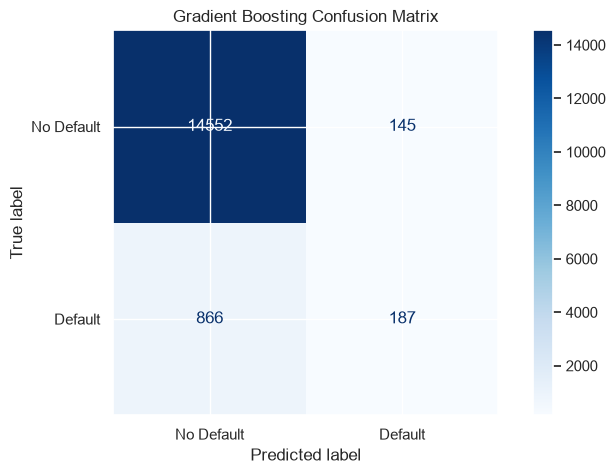

In [184]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    gb_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [185]:
train_auc = roc_auc_score(
    y_train,
    gb_baseline.predict_proba(X_train_processed)[:, 1]
)

val_auc = roc_auc_score(
    y_val,
    gb_baseline.predict_proba(X_val_processed)[:, 1]
)

print(f"Training AUC:   {train_auc:.4f}")
print(f"Validation AUC: {val_auc:.4f}")

Training AUC:   0.8782
Validation AUC: 0.8582


# Submission

Modelo final: mismos hiperparámetros que `gb_baseline`, reentrenado con **todo** `train.csv` (train + val + test splits).  
`test.csv` pasa por exactamente la misma limpieza (`clean_data`) e imputación.

In [ ]:
from sklearn.base import clone

# Todos los datos de train.csv (ya limpios, sin Id)
X_full = X.copy()
y_full = y.copy()

# Imputers nuevos, ajustados con todo train.csv (no se tocan los de la validación)
final_income_imputer = SimpleImputer(strategy="median").fit(X_full[["MonthlyIncome"]])
final_dependents_imputer = SimpleImputer(strategy="most_frequent").fit(X_full[["NumberOfDependents"]])
final_error_values_imputer = SimpleImputer(strategy="median").fit(X_full[ERROR_VALUE_COLS])

def impute_final(df):
    df = df.copy()
    df["MonthlyIncome"] = final_income_imputer.transform(df[["MonthlyIncome"]]).ravel()
    df["NumberOfDependents"] = final_dependents_imputer.transform(df[["NumberOfDependents"]]).ravel()
    df[ERROR_VALUE_COLS] = final_error_values_imputer.transform(df[ERROR_VALUE_COLS])
    return df

X_full_processed = impute_final(X_full)

In [ ]:
# Mismos hiperparámetros que gb_baseline, entrenado con todos los datos
final_model = clone(gb_baseline)
final_model.fit(X_full_processed, y_full)

In [ ]:
# Preparar test.csv igual que train
test_data = pd.read_csv("test.csv")
test_ids = test_data["Id"]

X_submission = clean_data(test_data).drop(columns=["Id"])
X_submission = impute_final(X_submission)
X_submission = X_submission[X_full_processed.columns]  # mismo orden de columnas que en el entrenamiento

submission = pd.DataFrame({
    "Id": test_ids,
    "SeriousDlqin2yrs": final_model.predict_proba(X_submission)[:, 1],  # probabilidades, no clases
})

In [ ]:
# Verificaciones antes de subir
sample_submission = pd.read_csv("sample_submission.csv")

assert list(submission.columns) == list(sample_submission.columns)
assert len(submission) == len(sample_submission)
assert submission["Id"].equals(sample_submission["Id"])          # mismos Ids, mismo orden
assert submission["SeriousDlqin2yrs"].notna().all()
assert submission["SeriousDlqin2yrs"].between(0, 1).all()

print("Filas:", len(submission))
print("Probabilidad media de default:", round(submission["SeriousDlqin2yrs"].mean(), 4),
      "(en train:", round(y_full.mean(), 4), ")")
submission.head()

In [ ]:
submission.to_csv("submission_gb_baseline.csv", index=False)